# LAB 04 — Text Classification: From Text Representation to Supervised NLP


---



## 1. Thiết lập môi trường & Nạp thư viện

In [ ]:
import os
import sys
import time
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from gensim.models import Word2Vec

SEED = 42
np.random.seed(SEED)
print("Tất cả thư viện đã được nạp thành công!")


Tất cả thư viện đã được nạp thành công!


## 2. Experiment 1 — Dataset Inspection (Khám phá dữ liệu)


In [ ]:
csv_path = '../dataset/IMDB Dataset.csv' if os.path.exists('../dataset/IMDB Dataset.csv') else 'dataset/IMDB Dataset.csv'
df = pd.read_csv(csv_path)
print(f"Tổng số mẫu trong dataset: {len(df):,}")
print(f"Số lượng cột: {df.shape[1]} ({list(df.columns)})")

missing_text = df['review'].isnull().sum()
missing_labels = df['sentiment'].isnull().sum()
empty_strings = (df['review'].str.strip() == '').sum()
print(f"Missing reviews: {missing_text}")
print(f"Missing labels: {missing_labels}")
print(f"Empty reviews: {empty_strings}")

num_duplicates = df.duplicated(subset=['review']).sum()
print(f"Số lượng văn bản trùng lặp (Duplicate reviews): {num_duplicates} ({num_duplicates/len(df)*100:.2f}%)")

df['word_count'] = df['review'].apply(lambda x: len(x.split()))
print("\nThống kê độ dài văn bản (Số từ mỗi bài đánh giá):")
print(df['word_count'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))


Tổng số mẫu trong dataset: 50,000
Số lượng cột: 2 (['review', 'sentiment'])
Missing reviews: 0
Missing labels: 0
Empty reviews: 0
Số lượng văn bản trùng lặp (Duplicate reviews): 418 (0.84%)



Thống kê độ dài văn bản (Số từ mỗi bài đánh giá):
count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
90%        451.000000
95%        590.000000
99%        908.000000
max       2470.000000
Name: word_count, dtype: float64


Bảng phân phối nhãn:
           Count  Percentage (%)
sentiment                       
positive   25000            50.0
negative   25000            50.0


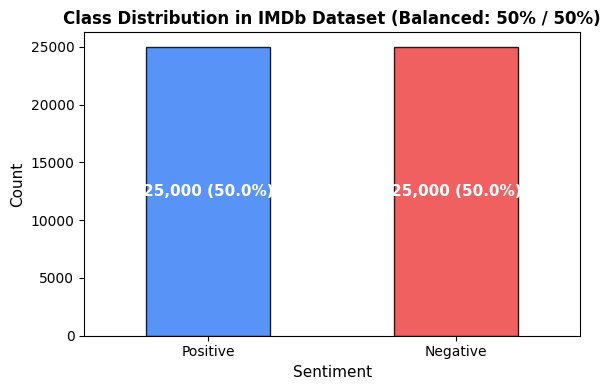

KẾT LUẬN VỀ IMBALANCE: Dataset hoàn toàn CÂN BẰNG TUYỆT ĐỐI (50% Positive, 50% Negative). Không có hiện tượng Class Imbalance.


In [ ]:
class_counts = df['sentiment'].value_counts()
class_pcts = df['sentiment'].value_counts(normalize=True) * 100

summary_dist = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_pcts
})
print("Bảng phân phối nhãn:")
print(summary_dist)

fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind='bar', color=['#3b82f6', '#ef4444'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title("Class Distribution in IMDb Dataset (Balanced: 50% / 50%)", fontsize=12, fontweight='bold')
ax.set_xlabel("Sentiment", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_xticklabels(["Positive", "Negative"], rotation=0)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,} ({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

print("KẾT LUẬN VỀ IMBALANCE: Dataset hoàn toàn CÂN BẰNG TUYỆT ĐỐI (50% Positive, 50% Negative). Không có hiện tượng Class Imbalance.")


## 3. Quy trình chuẩn mực chống rò rỉ dữ liệu (Preventing Data Leakage)



In [4]:
# Phân chia dữ liệu theo tỷ lệ chuẩn mực: 70% Train, 10% Validation, 20% Test
X_temp, X_test, y_temp, y_test = train_test_split(
    df['review'], df['sentiment'],
    test_size=0.20,
    random_state=SEED,
    stratify=df['sentiment']
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.125, # 0.125 * 0.8 = 0.10
    random_state=SEED,
    stratify=y_temp
)

print(f"Số lượng tập Train (70%):      {len(X_train):,} mẫu")
print(f"Số lượng tập Validation (10%): {len(X_val):,} mẫu")
print(f"Số lượng tập Test (20%):       {len(X_test):,} mẫu")


Số lượng tập Train (70%):      35,000 mẫu
Số lượng tập Validation (10%): 5,000 mẫu
Số lượng tập Test (20%):       10,000 mẫu


## 4. Module tiền xử lý văn bản (Preprocessing Utilities)

In [ ]:
def clean_text(text: str) -> str:
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenize(text: str):
    cleaned = clean_text(text).lower()
    return re.findall(r"\b[a-zA-Z]+(?:'[a-zA-Z]+)?\b", cleaned)

sample = "This movie was <b>NOT</b> good! <br /><br />Waste of time."
print("Gốc:", sample)
print("Sau làm sạch:", clean_text(sample))
print("Tokens:", tokenize(sample))


Gốc: This movie was <b>NOT</b> good! <br /><br />Waste of time.
Sau làm sạch: This movie was NOT good! Waste of time.
Tokens: ['this', 'movie', 'was', 'not', 'good', 'waste', 'of', 'time']


## 5. Experiment 2 — Baseline Implementation: TF-IDF (Unigram) + Logistic Regression 

In [ ]:
t0 = time.time()
tfidf_unigram = TfidfVectorizer(max_features=25000, preprocessor=clean_text, stop_words='english')

X_train_tfidf_uni = tfidf_unigram.fit_transform(X_train)
X_val_tfidf_uni = tfidf_unigram.transform(X_val)
X_test_tfidf_uni = tfidf_unigram.transform(X_test)
tfidf_uni_time = time.time() - t0

t1 = time.time()
clf_lr_baseline = LogisticRegression(max_iter=1000, random_state=SEED, C=1.0)
clf_lr_baseline.fit(X_train_tfidf_uni, y_train)
lr_baseline_time = time.time() - t1
total_baseline_time = tfidf_uni_time + lr_baseline_time

y_pred_baseline = clf_lr_baseline.predict(X_test_tfidf_uni)
acc_baseline = accuracy_score(y_test, y_pred_baseline)
prec_baseline = precision_score(y_test, y_pred_baseline, pos_label='positive')
rec_baseline = recall_score(y_test, y_pred_baseline, pos_label='positive')
f1_baseline = f1_score(y_test, y_pred_baseline, pos_label='positive')

print(f"=== KẾT QUẢ BASELINE (TF-IDF Unigram + Logistic Regression) ===")
print(f"Kích thước từ điển (Vocab size): {len(tfidf_unigram.vocabulary_):,}")
print(f"Thời gian huấn luyện:            {total_baseline_time:.2f}s")
print(f"Accuracy:                         {acc_baseline*100:.2f}%")
print(f"Precision:                        {prec_baseline*100:.2f}%")
print(f"Recall:                           {rec_baseline*100:.2f}%")
print(f"F1-Score:                         {f1_baseline*100:.2f}%")


=== KẾT QUẢ BASELINE (TF-IDF Unigram + Logistic Regression) ===
Kích thước từ điển (Vocab size): 25,000
Thời gian huấn luyện:            11.52s
Accuracy:                         89.62%
Precision:                        88.69%
Recall:                           90.82%
F1-Score:                         89.74%


## 6. Experiment 3 — So sánh các phương pháp biểu diễn văn bản 
So sánh:
* **Model A:** TF-IDF (Unigram) + Logistic Regression (Baseline)
* **Model B:** Average Word2Vec + Logistic Regression
* **Model C:** TF-IDF (Unigram) + Linear SVM
* **Model D:** TF-IDF (Uni + Bigram) + Logistic Regression
* **Model E:** TF-IDF (Uni + Bigram) + Linear SVM


In [ ]:
train_tokens = [tokenize(doc) for doc in X_train]
t0 = time.time()
w2v_model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4, epochs=5, seed=SEED)
w2v_train_time = time.time() - t0
print(f"Word2Vec huấn luyện xong trong {w2v_train_time:.2f}s, kích thước vocab: {len(w2v_model.wv):,}")

def docs_to_avg_w2v(docs, w2v, dim=100):
    wv = w2v.wv
    matrix = np.zeros((len(docs), dim), dtype=np.float32)
    for i, doc in enumerate(docs):
        tokens = tokenize(doc)
        vecs = [wv[w] for w in tokens if w in wv]
        if len(vecs) > 0:
            matrix[i] = np.mean(vecs, axis=0)
    return matrix

t0 = time.time()
X_train_w2v = docs_to_avg_w2v(X_train, w2v_model)
X_test_w2v = docs_to_avg_w2v(X_test, w2v_model)
feat_w2v_time = time.time() - t0

t1 = time.time()
clf_lr_w2v = LogisticRegression(max_iter=1000, random_state=SEED, C=1.0)
clf_lr_w2v.fit(X_train_w2v, y_train)
lr_w2v_time = time.time() - t1
total_w2v_time = w2v_train_time + feat_w2v_time + lr_w2v_time

y_pred_w2v = clf_lr_w2v.predict(X_test_w2v)
acc_w2v = accuracy_score(y_test, y_pred_w2v)
prec_w2v = precision_score(y_test, y_pred_w2v, pos_label='positive')
rec_w2v = recall_score(y_test, y_pred_w2v, pos_label='positive')
f1_w2v = f1_score(y_test, y_pred_w2v, pos_label='positive')
print(f"Model B (Avg Word2Vec + LR) -> Accuracy: {acc_w2v*100:.2f}%, F1: {f1_w2v*100:.2f}%")


Word2Vec huấn luyện xong trong 15.86s, kích thước vocab: 57,648


Model B (Avg Word2Vec + LR) -> Accuracy: 84.32%, F1: 84.39%


In [ ]:
t0 = time.time()
clf_svm_uni = LinearSVC(random_state=SEED, max_iter=2000, C=1.0)
clf_svm_uni.fit(X_train_tfidf_uni, y_train)
svm_uni_time = time.time() - t0 + tfidf_uni_time

y_pred_svm_uni = clf_svm_uni.predict(X_test_tfidf_uni)
acc_svm_uni = accuracy_score(y_test, y_pred_svm_uni)
prec_svm_uni = precision_score(y_test, y_pred_svm_uni, pos_label='positive')
rec_svm_uni = recall_score(y_test, y_pred_svm_uni, pos_label='positive')
f1_svm_uni = f1_score(y_test, y_pred_svm_uni, pos_label='positive')
print(f"Model C (TF-IDF Unigram + Linear SVM) -> Accuracy: {acc_svm_uni*100:.2f}%, F1: {f1_svm_uni*100:.2f}%")


Model C (TF-IDF Unigram + Linear SVM) -> Accuracy: 89.17%, F1: 89.21%


## 7. Experiment 5 — Mở rộng đặc trưng n-gram 

In [ ]:
t0 = time.time()
tfidf_bigram = TfidfVectorizer(ngram_range=(1, 2), max_features=50000, preprocessor=clean_text)
X_train_tfidf_bi = tfidf_bigram.fit_transform(X_train)
X_test_tfidf_bi = tfidf_bigram.transform(X_test)
tfidf_bi_time = time.time() - t0

t1 = time.time()
clf_lr_bigram = LogisticRegression(max_iter=1000, random_state=SEED, C=1.0)
clf_lr_bigram.fit(X_train_tfidf_bi, y_train)
lr_bi_time = time.time() - t1
total_bi_time = tfidf_bi_time + lr_bi_time

y_pred_bigram = clf_lr_bigram.predict(X_test_tfidf_bi)
acc_bigram = accuracy_score(y_test, y_pred_bigram)
prec_bigram = precision_score(y_test, y_pred_bigram, pos_label='positive')
rec_bigram = recall_score(y_test, y_pred_bigram, pos_label='positive')
f1_bigram = f1_score(y_test, y_pred_bigram, pos_label='positive')

t2 = time.time()
clf_svm_bi = LinearSVC(random_state=SEED, max_iter=2000, C=1.0)
clf_svm_bi.fit(X_train_tfidf_bi, y_train)
svm_bi_time = time.time() - t2 + tfidf_bi_time

y_pred_svm_bi = clf_svm_bi.predict(X_test_tfidf_bi)
acc_svm_bi = accuracy_score(y_test, y_pred_svm_bi)
prec_svm_bi = precision_score(y_test, y_pred_svm_bi, pos_label='positive')
rec_svm_bi = recall_score(y_test, y_pred_svm_bi, pos_label='positive')
f1_svm_bi = f1_score(y_test, y_pred_svm_bi, pos_label='positive')

print(f"Model D (TF-IDF Uni+Bigram + LR) -> Accuracy: {acc_bigram*100:.2f}%, F1: {f1_bigram*100:.2f}%")
print(f"Model E (TF-IDF Uni+Bigram + SVM) -> Accuracy: {acc_svm_bi*100:.2f}%, F1: {f1_svm_bi*100:.2f}%")


Model D (TF-IDF Uni+Bigram + LR) -> Accuracy: 90.42%, F1: 90.48%
Model E (TF-IDF Uni+Bigram + SVM) -> Accuracy: 91.19%, F1: 91.23%


In [ ]:
benchmark_data = [
    {"Model": "Baseline (TF-IDF Unigram + LR)", "Representation": "TF-IDF (Unigram)", "Classifier": "Logistic Regression", "Vocabulary_Size": len(tfidf_unigram.vocabulary_), "Accuracy": round(acc_baseline, 4), "Precision": round(prec_baseline, 4), "Recall": round(rec_baseline, 4), "F1_Score": round(f1_baseline, 4), "Training_Time_Sec": round(total_baseline_time, 2)},
    {"Model": "Model B (Avg Word2Vec + LR)", "Representation": "Average Word2Vec (100d)", "Classifier": "Logistic Regression", "Vocabulary_Size": len(w2v_model.wv), "Accuracy": round(acc_w2v, 4), "Precision": round(prec_w2v, 4), "Recall": round(rec_w2v, 4), "F1_Score": round(f1_w2v, 4), "Training_Time_Sec": round(total_w2v_time, 2)},
    {"Model": "Model C (TF-IDF Unigram + Linear SVM)", "Representation": "TF-IDF (Unigram)", "Classifier": "Linear SVM", "Vocabulary_Size": len(tfidf_unigram.vocabulary_), "Accuracy": round(acc_svm_uni, 4), "Precision": round(prec_svm_uni, 4), "Recall": round(rec_svm_uni, 4), "F1_Score": round(f1_svm_uni, 4), "Training_Time_Sec": round(svm_uni_time, 2)},
    {"Model": "Model D (TF-IDF Uni+Bigram + LR)", "Representation": "TF-IDF (Uni + Bigram)", "Classifier": "Logistic Regression", "Vocabulary_Size": len(tfidf_bigram.vocabulary_), "Accuracy": round(acc_bigram, 4), "Precision": round(prec_bigram, 4), "Recall": round(rec_bigram, 4), "F1_Score": round(f1_bigram, 4), "Training_Time_Sec": round(total_bi_time, 2)},
    {"Model": "Model E (TF-IDF Uni+Bigram + Linear SVM)", "Representation": "TF-IDF (Uni + Bigram)", "Classifier": "Linear SVM", "Vocabulary_Size": len(tfidf_bigram.vocabulary_), "Accuracy": round(acc_svm_bi, 4), "Precision": round(prec_svm_bi, 4), "Recall": round(rec_svm_bi, 4), "F1_Score": round(f1_svm_bi, 4), "Training_Time_Sec": round(svm_bi_time, 2)},
]

benchmark_df = pd.DataFrame(benchmark_data)
benchmark_df.to_csv('results.csv', index=False)
benchmark_df


,Model,Representation,Classifier,Vocabulary_Size,Accuracy,Precision,Recall,F1_Score,Training_Time_Sec
0,Baseline (TF-IDF Unigram + LR),TF-IDF (Unigram),Logistic Regression,25000,0.8962,0.8869,0.9082,0.8974,11.52
1,Model B (Avg Word2Vec + LR),Average Word2Vec (100d),Logistic Regression,57648,0.8432,0.8403,0.8474,0.8439,37.83
2,Model C (TF-IDF Unigram + Linear SVM),TF-IDF (Unigram),Linear SVM,25000,0.8917,0.8887,0.8956,0.8921,9.60
3,Model D (TF-IDF Uni+Bigram + LR),TF-IDF (Uni + Bigram),Logistic Regression,50000,0.9042,0.8989,0.9108,0.9048,42.67
4,Model E (TF-IDF Uni+Bigram + Linear SVM),TF-IDF (Uni + Bigram),Linear SVM,50000,0.9119,0.9077,0.9170,0.9123,40.91


## 8. Experiment 4 — Thí nghiệm về trật tự từ & Hiện tượng phủ định 
Cho hai câu văn:
* $S_1 = \text{"this movie is good"}$
* $S_2 = \text{"this movie is not good"}$


In [ ]:
s1 = "this movie is good"
s2 = "this movie is not good"

def get_sentence_w2v(s, w2v):
    tokens = s.lower().split()
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.mean(vecs, axis=0)

v1 = get_sentence_w2v(s1, w2v_model)
v2 = get_sentence_w2v(s2, w2v_model)

cos_sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
print(f"Câu S1: '{s1}'")
print(f"Câu S2: '{s2}'")
print(f"Độ tương đồng Cosine giữa S1 và S2 trong Average Word2Vec: {cos_sim:.4f}")
print("Dự đoán S1 (Avg Word2Vec + LR):", clf_lr_w2v.predict([v1])[0])
print("Dự đoán S2 (Avg Word2Vec + LR):", clf_lr_w2v.predict([v2])[0])

v1_bi = tfidf_bigram.transform([s1])
v2_bi = tfidf_bigram.transform([s2])
print("\nDự đoán S1 (TF-IDF Uni+Bigram + LR):", clf_lr_bigram.predict(v1_bi)[0])
print("Dự đoán S2 (TF-IDF Uni+Bigram + LR):", clf_lr_bigram.predict(v2_bi)[0])


Câu S1: 'this movie is good'
Câu S2: 'this movie is not good'
Độ tương đồng Cosine giữa S1 và S2 trong Average Word2Vec: 0.9543
Dự đoán S1 (Avg Word2Vec + LR): positive
Dự đoán S2 (Avg Word2Vec + LR): negative

Dự đoán S1 (TF-IDF Uni+Bigram + LR): positive
Dự đoán S2 (TF-IDF Uni+Bigram + LR): negative


## 9. Đánh giá chi tiết & Ma trận nhầm lẫn 

Classification Report cho Model D:
              precision    recall  f1-score   support

    negative     0.9096    0.8976    0.9036      5000
    positive     0.8989    0.9108    0.9048      5000

    accuracy                         0.9042     10000
   macro avg     0.9043    0.9042    0.9042     10000
weighted avg     0.9043    0.9042    0.9042     10000



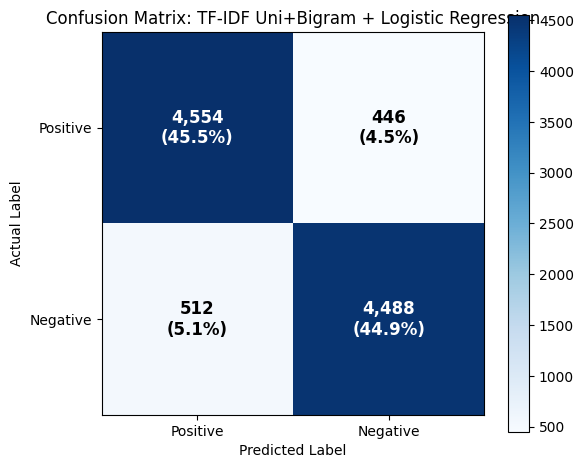

In [ ]:
cm = confusion_matrix(y_test, y_pred_bigram, labels=['positive', 'negative'])
print("Classification Report cho Model D:")
print(classification_report(y_test, y_pred_bigram, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
classes = ['Positive', 'Negative']
ax.set(xticks=np.arange(cm.shape[1]),
       yticks=np.arange(cm.shape[0]),
       xticklabels=classes, yticklabels=classes,
       title='Confusion Matrix: TF-IDF Uni+Bigram + Logistic Regression',
       ylabel='Actual Label',
       xlabel='Predicted Label')

thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        pct = val / cm.sum() * 100
        ax.text(j, i, f"{val:,}\n({pct:.1f}%)",
                ha="center", va="center",
                color="white" if val > thresh else "black",
                fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()


## 10. Khám phá trọng số mô hình 
Phân tích tính giải thích (Model Interpretability) thông qua trọng số của Logistic Regression ($z = w^T x + b$).


In [13]:
feature_names = np.array(tfidf_bigram.get_feature_names_out())
coefs = clf_lr_bigram.coef_[0]

top_pos_idx = np.argsort(coefs)[-15:][::-1]
top_neg_idx = np.argsort(coefs)[:15]

top_pos_df = pd.DataFrame({'Feature': feature_names[top_pos_idx], 'Weight (wi >> 0)': coefs[top_pos_idx]})
top_neg_df = pd.DataFrame({'Feature': feature_names[top_neg_idx], 'Weight (wi << 0)': coefs[top_neg_idx]})

print("=== TOP 15 ĐẶC TRƯNG TÍCH CỰC (Đẩy mạnh dự đoán Positive) ===")
print(top_pos_df.to_string(index=False))

print("\n=== TOP 15 ĐẶC TRƯNG TIÊU CỰC (Đẩy mạnh dự đoán Negative) ===")
print(top_neg_df.to_string(index=False))


=== TOP 15 ĐẶC TRƯNG TÍCH CỰC (Đẩy mạnh dự đoán Positive) ===
  Feature  Weight (wi >> 0)
    great          7.707298
excellent          5.774659
  perfect          4.980423
     well          4.785204
wonderful          4.634908
  amazing          4.589166
 the best          4.537747
      and          4.001856
      fun          3.884534
     love          3.835324
    today          3.695965
  enjoyed          3.661486
hilarious          3.638524
     best          3.561500
    loved          3.497364

=== TOP 15 ĐẶC TRƯNG TIÊU CỰC (Đẩy mạnh dự đoán Negative) ===
  Feature  Weight (wi << 0)
      bad         -8.991879
    worst         -7.931448
    awful         -6.962534
the worst         -6.297884
   boring         -6.267982
    waste         -5.945861
     poor         -5.569367
 terrible         -5.336179
  nothing         -4.980597
   stupid         -4.465118
    worse         -4.420481
     dull         -4.353404
   poorly         -4.227127
 horrible         -4.101650
  minut

## 11. Phân tích lỗi
Trích xuất ít nhất 3 mẫu dự đoán đúng và 3 mẫu dự đoán sai trên tập kiểm thử để phân tích chất lượng.


In [14]:
test_df = pd.DataFrame({
    'text': X_test.values,
    'true_label': y_test.values,
    'pred_label': y_pred_bigram,
    'pred_prob_pos': clf_lr_bigram.predict_proba(X_test_tfidf_bi)[:, 1]
})

correct = test_df[test_df['true_label'] == test_df['pred_label']]
errors = test_df[test_df['true_label'] != test_df['pred_label']]

print(f"Tổng số mẫu đúng: {len(correct):,} ({len(correct)/len(test_df)*100:.2f}%)")
print(f"Tổng số mẫu sai:  {len(errors):,} ({len(errors)/len(test_df)*100:.2f}%)")

print("\n--- 3 MẪU DỰ ĐOÁN ĐÚNG TIÊU BIỂU ---")
for i, idx in enumerate(correct.index[:3]):
    row = correct.loc[idx]
    print(f"\n[Đúng {i+1}] Thực tế: {row['true_label']} | Dự đoán: {row['pred_label']} | P(Pos): {row['pred_prob_pos']:.4f}")
    print("Văn bản:", row['text'][:300], "...")

print("\n--- 3 MẪU DỰ ĐOÁN SAI TIÊU BIỂU (ERROR ANALYSIS) ---")
for i, idx in enumerate(errors.index[:3]):
    row = errors.loc[idx]
    print(f"\n[Sai {i+1}] Thực tế: {row['true_label']} | Dự đoán: {row['pred_label']} | P(Pos): {row['pred_prob_pos']:.4f}")
    print("Văn bản:", row['text'][:300], "...")


Tổng số mẫu đúng: 9,042 (90.42%)
Tổng số mẫu sai:  958 (9.58%)

--- 3 MẪU DỰ ĐOÁN ĐÚNG TIÊU BIỂU ---

[Đúng 1] Thực tế: positive | Dự đoán: positive | P(Pos): 0.8404
Văn bản: A team varied between Scully and Mulder, two other scientists, a pilot, and the guy who plays Bana on Seinfeld, go up to an Arctic research post where all members have died off by either killing each other or killing themselves. They discover there's a worm- a virus- that is parasitic to the point o ...

[Đúng 2] Thực tế: negative | Dự đoán: negative | P(Pos): 0.2602
Văn bản: This was a popular movie probably because of the humor in it, the fast-moving story, an underdog character who shuts up all the loudmouths, etc. Funny thing is, you probably couldn't make a movie with this title if you substituted anybody but "white" as anything else would be deemed racist by the PC ...

[Đúng 3] Thực tế: negative | Dự đoán: negative | P(Pos): 0.1027
Văn bản: This movie made me so angry!! Here I am thinking that here's a new 